# Transformers and flow matching from scratch, in JAX

First of all, let's build a transformer from scratch, and teach it to do regression **in context**: every training
example is a *different* function, and the network only sees a handful of noisy points from it. Nothing about
any one function can actually be stored in the weights, but the model has to work it out from its input.

In the second half, we will reuse the same network as the velocity field of a **flow matching** model, and draw from the posterior
of functions that are consistent with the data.

The functions are drawn from a Gaussian process with a random lengthscale, so the best possible answer is known
exactly. It will be given by `gp_posterior`.

In [ ]:
# !pip install -q jax jaxlib matplotlib
!pip install optax

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import optax

print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.11.2 | devices: [CpuDevice(id=0)]


## The data


In [7]:
X_MAX = 2.0
NOISE_STD = 0.05
ELL_MIN, ELL_MAX = 0.2, 1.0


def rbf(x1, x2, ell):
    """x1: (b, n), x2: (b, m), ell: (b,) -> (b, n, m)"""
    return jnp.exp(-0.5 * (x1[:, :, None] - x2[:, None, :]) ** 2 / ell[:, None, None] ** 2)


def sample_tasks(key, batch, n_ctx, n_tgt=32, ell=None, x_tgt=None):
    """Draw `batch` random functions, each observed (with noise) at n_ctx context and n_tgt target points.
    Returns xc, yc: (batch, n_ctx)   xt, yt: (batch, n_tgt)   ell: (batch,)"""
    k_ell, k_xc, k_xt, k_y = jax.random.split(key, 4)
    if ell is None:
        ell = jnp.exp(jax.random.uniform(k_ell, (batch,), minval=np.log(ELL_MIN), maxval=np.log(ELL_MAX)))
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (batch,))
    xc = jax.random.uniform(k_xc, (batch, n_ctx), minval=-X_MAX, maxval=X_MAX)
    if x_tgt is None:
        xt = jax.random.uniform(k_xt, (batch, n_tgt), minval=-X_MAX, maxval=X_MAX)
    else:
        xt = jnp.broadcast_to(x_tgt, (batch, x_tgt.shape[-1]))
    x = jnp.concatenate([xc, xt], axis=1)
    K = rbf(x, x, ell) + (NOISE_STD**2 + 1e-5) * jnp.eye(x.shape[1])
    y = jnp.einsum("bij,bj->bi", jnp.linalg.cholesky(K), jax.random.normal(k_y, x.shape))
    return xc, y[:, :n_ctx], xt, y[:, n_ctx:], ell


def gp_posterior(xc, yc, xt, ell):
    """Exact GP prediction at xt given (xc, yc), if you knew the lengthscale.
    Returns mean: (b, n_tgt), cov: (b, n_tgt, n_tgt)"""
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (xc.shape[0],))
    Kcc = rbf(xc, xc, ell) + NOISE_STD**2 * jnp.eye(xc.shape[1])
    Ktc = rbf(xt, xc, ell)
    Ktt = rbf(xt, xt, ell) + NOISE_STD**2 * jnp.eye(xt.shape[1])
    A = jnp.linalg.solve(Kcc, jnp.swapaxes(Ktc, 1, 2))
    mean = jnp.einsum("bct,bc->bt", A, yc)
    return mean, Ktt - Ktc @ A


xc, yc, xt, yt, ell = sample_tasks(jax.random.key(0), batch=1000, n_ctx=10)
mean, cov = gp_posterior(xc, yc, xt, ell)

print(f"target variance               : {float(yt.var()):.4f}")   # predict 0 everywhere
print(f"GP error, 10 points, true ell : {float(((mean - yt) ** 2).mean()):.4f}")   # the best you can do

target variance               : 0.9791
GP error, 10 points, true ell : 0.1456


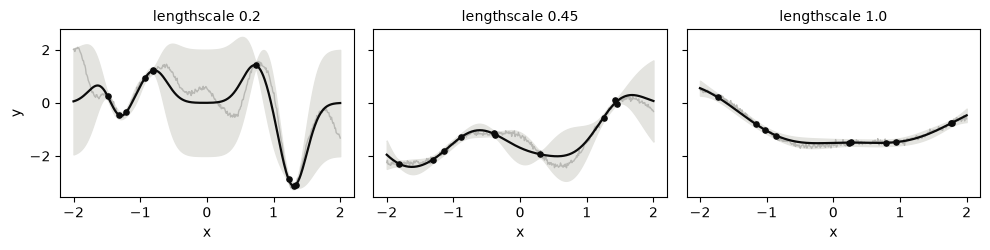

In [8]:
grid = jnp.linspace(-X_MAX, X_MAX, 400)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, ell_, key in zip(axes, [0.2, 0.45, 1.0], jax.random.split(jax.random.key(1), 3)):
    xc, yc, xt, yt, _ = sample_tasks(key, 1, n_ctx=10, ell=ell_, x_tgt=grid)
    mean, cov = gp_posterior(xc, yc, grid[None], ell_)
    std = jnp.sqrt(jnp.diagonal(cov[0]))
    ax.fill_between(np.array(grid), np.array(mean[0] - 2 * std), np.array(mean[0] + 2 * std), color="#e4e4e0")
    ax.plot(np.array(grid), np.array(yt[0]), color="#b8b8b4", lw=1)
    ax.plot(np.array(grid), np.array(mean[0]), color="#0b0b0b", lw=1.6)
    ax.scatter(np.array(xc[0]), np.array(yc[0]), s=14, color="#0b0b0b", zorder=3)
    ax.set_title(f"lengthscale {ell_}", fontsize=10); ax.set_xlabel("x")
axes[0].set_ylabel("y"); plt.tight_layout(); plt.show()

---
## 1. Attention

Every observed point becomes a token `(x, y, 1)`; every point where you want a prediction is also  a token
`(x, 0, 0)`.

Write multi-head self-attention, `attention(params, h, mask)`, where `mask[i, j]` says whether token `i` may look
at token `j`. Then a transformer block: layer norm, attention, residual, MLP, residual.

Choose the mask.  What are targets allowed to look at? should they receive information from other targets?

In [ ]:
def init_attention(key, width,n_heads):
    """Initiates the weights for the attention network.
    params: 
    Key: int, jax  key for randomization
    width: int, embedding dimension
    n_heads: int, number of attention heads
    returns: four matrices to be learned"""

    k1, k2, k3, k4 = jax.random.split(key,4)
    queries = jax.random.normal(k1,shape=(width,width)) / jnp.sqrt(width)
    keys    = jax.random.normal(k2,shape=(width,width)) / jnp.sqrt(width)
    values  = jax.random.normal(k3,shape=(width,width)) / jnp.sqrt(width)
    # output projection mixes info from across heads
    output_projection = jax.random.normal(k4,shape=(width,width)) / jnp.sqrt(width)
    return (queries, keys, values, output_projection)
    

def attention(params, tokens, mask, n_heads):
    """Runs the attention mechanism forward"""
    n_tokens = len(tokens[:,0])
    width = len(tokens[0,:])
    d_k = width // n_heads # length of each head
    
    # pass the learned weights as parameters
    query_matrix, key_matrix, value_matrix, output_projection = params

    # query vector for each token is the token's embedding times the query weight matrix
    Q = jnp.matmul(tokens,query_matrix) # has shape (n_tokens, width)
    K = jnp.matmul(tokens,key_matrix) # has shape (n_tokens, width)
    V = jnp.matmul(tokens,value_matrix) # shape (n_tokens, width)

    # split into multiple heads
    outputs = []
    for h in range(n_heads):
        i_start = h*d_k
        i_stop = i_start + d_k
        # split matrices into block for just this head
        Q_h = Q[:,i_start:i_stop]
        K_h = K[:,i_start:i_stop]
        V_h = V[:,i_start:i_stop]
        scores_h = Q_h @ K_h.T / jnp.sqrt(d_k)
        # apply mask so tokens only read context points, not target points
        # jnp.where replaces all instances of False in mask with -inf
        scores_h = jnp.where(mask,scores_h,-jnp.inf)
        output_h = jax.nn.softmax(scores_h, axis=-1) @ V_h
        outputs.append(output_h)
    output = jnp.concatenate(outputs,axis=-1)
    output_mixedheads = output @ output_projection
    return output_mixedheads

def layernorm(tokens,gamma,beta,eps = 1e-5):
    """ compute layer norm on each token's embedding vector
    input: tokens: list of embedded tokens
    eps: used to avoid dividing by 0
    gamma, beta are learned params, need to be trained"""
    mean = jnp.mean(tokens,axis=-1,keepdims=True)
    var = jnp.var(tokens,axis=-1,keepdims=True)
    tokens = (tokens-mean)/jnp.sqrt(var+eps) # should subtract mean from each token's vector
    tokens = gamma*tokens + beta
    return tokens

Check this by running n_heads = 1 and compare to full attention with no splitting

---
## 2. The transformer

Embed the tokens (a small MLP is fine), stack transformer blocks, and read out a mean and a log-variance at each target.
We will assume a Gaussian negative log-likelihood during training. Some reasonable numbers are width 64, 4 heads, 4 layers.

Each step: get a batch of functions, with a random number of context points between 3 and 30, and 30'ish targets as well. 
Feel free to use jax libraries for the optimiser and weight updates (no need to use your solution from the previous tutorial!). 
The number of context points changes the shapes, so `jax.jit` recompiles once per value. That's fine, otherwise you'd need to add some padding

Build the embedding MLP: this model should take the 3 input values for each token (x,y, isContext) (isContext = 1 if context point and = 0 if target point)
and return a vector len 64.

In [ ]:
# Build the embedding MLP
# This model should take the 3 values of tokens (x)
def init_mlp(key,layer_sizes):
    n_layers = len(layer_sizes)
    keys = jax.random.split(key,2*(n_layers - 1)) # only need weights and biases for hidden and final layer
    biases = []
    weights = []
    for i, size in enumerate(layer_sizes[1:]): # don't need weights + biases for input layer
        std = jnp.sqrt(2 / layer_sizes[i])
        bias = jax.random.normal(keys[2*i],size) / 10 # try initialize with non-zero biases
        weight = jax.random.normal(keys[2*i+1],(layer_sizes[i]),size) * std
        biases.append(bias)
        weights.append(weight)
    return (weights, biases)

def mlp(params,tokens):
    """Embeds the list of tokens (x,y,isContext) into 64 dim vectors
    inputs:
    params: tuple (weights, biases) with size (n_layers, n_layers)
    tokens: list of tuples for each context+target token

    returns: list of embedding vectors for each token"""
    n_layers = len(params[0]) # length of weights list
    a = tokens
    for i in range(n_layers):
        W = params[0][i]
        b = params[1][i]
        if i < n_layers-1: a = jax.nn.gelu(a @ W + b)
        else: a = a @ W + b
    return a

Create the transformer block: layer norm, attention, residual, MLP, residual

def transformer(n_blocks):

In [ ]:
def init_params(key,embedding_dim=64,
                n_heads=4,embedding_size=(3,64,64),umembedding_size=(64,64,2),
                forward_mlp_size=(64,64*4,64),n_blocks=4):
    k_embed, k_unemb = jax.random.split(key,3)
    k_forward = jax.random.split(key,n_blocks)
    k_atts = jax.random.split(key,n_blocks)
    
    embedding_params = init_mlp(k_embed,embedding_size)
    
    unembedding_params = init_mlp(k_unemb,umembedding_size)
    # store one copy of MLP params for each block using dict
    # and one copy of attention params for each block
    forward_mlp_params = {}
    for block in range(n_blocks):
        k_thisforward = k_forward[block]
        k_att = k_atts[block]
        forward_mlp_params[f"block_{block}"] = init_mlp(k_thisforward,forward_mlp_size)
        attention_params = init_attention(k_att,embedding_dim,n_heads)

    gamma = jnp.ones(embedding_dim)
    beta = jnp.zeros(embedding_dim)

    return embedding_params, attention_params,forward_mlp_params,unembedding_params,gamma,beta

def transformer(params,tokens_raw,n_heads,n_blocks=4):
    # call params
    embedding_params, attention_params,forward_mlp_params,unembedding_params,gamma,beta = params
    # embed tokens
    tokens = mlp(embedding_params,tokens_raw) # embedded tokens

    #TODO: make mask
    mask = []


    # do layer norm->attention->residual->MLP->residual for each block
    for block in range(n_blocks):
        tokens = layernorm(tokens,gamma,beta)
        tokens += attention(attention_params,tokens,mask,n_heads)
        forward_params = forward_mlp_params[f"block_{block}"]
        tokens += mlp(forward_params,tokens)

    #apply final layer norm after last block
    tokens = layernorm(tokens,gamma,beta)
    # use MLP to unembed: send token vectors -> (x,y)
    
    output_unembedded = mlp(unembedding_params,tokens) # shape (n_tokens,2), each output [predicted y, log of pred var)
    return output_unembedded

def loss_fn(out,target_y,n_ctx):
    """target_y is a list of predicted y values for target points"""
    # calculate loss for one batch (one set of target points)
    y_pred = out[n_ctx:,0] # mean
    log_var = out[n_ctx:,1]
    neg_log_likehood = 0.5 * (log_var + (y_pred - target_y)**2 * jnp.exp(-log_var)) # array of len n target pts
    return jnp.mean(log_likehood)

# in implementation, will need to run loss over all all function batches.

In [ ]:
def make_tokens(xc, yc, xt):
    x_all = jnp.concatenate([xc,xt],axis=1)
    y_all = jnp.concatenate([yc,jnp.zeros_like(yc)],axis=1)
    flags = jnp.concatenate([jnp.ones_like(xc),jnp.zeros_like(xt)],axis=1)
    tokens = jnp.stack([x_all,y_all,flags],axis=-1)
    return tokens

def make_mask(n_ctx,n_tgt):
    n = n_ctx + n_tgt
    mask = jnp.zeros((n,n),dtype=bool)
    # block diagonal boolean matrix
    # all context sees context, tgt sees context should be True
    mask = mask.at[:n_ctx,:n_ctx].set(True)
    mask = mask.at[n_ctx:,:n_ctx].set(True)
    return mask

In [ ]:
# run the transformer forward
def forward(key,batch,n_ctx):
    k_sample, k_trans = jax.random.split(key,2)

    # first generate the fxn points
    xc, yc, xt, yt, ell = sample_tasks(k_sample,batch,n_ctx)
    context_pts = (xc, yc, 1)
    target_pts = (xt, 0, 0)
    input_tokens = context_pts + target_pts
    transformer_output = transformer(input_tokens,k_trans)
    loss_out = loss(transformer_output,target_pts[1])
    return loss_out

def train_step(params,opt_state,xc,yc,xt,yt):
    loss, grads = jax.value_and_grad(loss_fn)(params)
    updates, opt_state = opt.update(grads,opt_state,params)
    params = optax.apply_updates(params,updates)
    return params, opt_state

In [ ]:
# training
opt = optax.adam(1e-3)
key = jax.random.key(19)

params = init_params(key)
opt_state = opt.init(params)





---
## 3. An MLP, for comparison

Give an MLP the same job: flatten the context, zero-padded up to 30 points with a mask, and append the query
`x`. Train it the same way.

---
## 4. Results 

- **Test error against the number of context points**, from 3 to 80, log-log, for the transformer, the MLP,
  and `gp_posterior` with the true lengthscale
- What happens to each model's predictions when you **shuffle the context points**?
- Plot something I didn't ask for!

---
## 5. Flow matching

Now generate posteriors over functions. Target tokens carry a noisy value $y_t$ instead of 0, the time $t$ is embedded and added
to every token, and the head outputs one velocity per target. Same network as before.

Train on the straight path from noise $\epsilon \sim \mathcal{N}(0, 1)$ to data:

$$y_t = (1-t)\,\epsilon + t\,y, \qquad \mathcal{L} = \big\| v_\theta(y_t, t \mid \text{context}) - (y - \epsilon) \big\|^2$$

Sample by integrating $dy/dt = v_\theta$ from $t=0$ to $1$ with Euler, 50 steps.